# 81 字形近汉字基线 · Colab

先完成 GPU 检查、数据检查和短跑，再启动 40 epoch 基线。所有训练输出写入 Google Drive；
四份数据复制到 `/content` 后使用。当前研究边界是固定思源黑体的合成单字识别。

**首次使用**
1. 在 Google Drive 的“我的云端硬盘”下建立 `hanzi81` 文件夹，把 `hanzi81_colab_bundle.zip` 上传进去。
2. 在 Colab 上传此 Notebook，并“在云端硬盘中保存副本”。
3. 菜单“运行时／代码执行程序 → 更改运行时类型”选择 Python 3、GPU。先选可用的 T4；无需为本轮优先选最昂贵的 GPU。
4. 从上到下逐格执行。遇到红色错误就停在该格。完整训练默认关闭，短跑正常后按第 7 步开启。

已有 Pro／算力额度不代表固定 GPU 或无限运行时。断线后重连并重跑前面的准备格，再运行相同的训练格，会从最近完成的 epoch 恢复。
更换 GPU 型号、软件版本、数据或超参数时不能声称逐步一致续训，脚本会要求新建 run。
参考：[Colab 官方 FAQ](https://research.google.com/colaboratory/faq.html)。


## 1. 确认 GPU 与预装 PyTorch

使用 Colab 预装的 torch/torchvision 配套组合，不运行 `pip install -U torch`。
上传包已包含生成好的数据，不需要在 GPU 会话中重新渲染。版本和设备信息会写入每次实验配置。


In [ ]:
import os, sys, json, subprocess, hashlib, shutil, zipfile
from pathlib import Path
import torch, torchvision, numpy as np
print('Python:', sys.version)
print('PyTorch:', torch.__version__, 'Torchvision:', torchvision.__version__)
assert torch.cuda.is_available(), '未分配到 GPU：更改运行时类型为 GPU，再重新连接。'
print('GPU:', torch.cuda.get_device_name(0))
print('显存 GiB:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
subprocess.run(['nvidia-smi'], check=True)
with torch.no_grad():
    probe = torch.nn.Conv2d(1, 8, 3).cuda()
    print('GPU 前向检查:', tuple(probe(torch.zeros(2, 1, 64, 64, device='cuda')).shape))
del probe
torch.cuda.empty_cache()


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130 Torchvision: 0.26.0+cu130
GPU: Tesla T4
显存 GiB: 14.6
GPU 前向检查: (2, 8, 62, 62)


## 2. 连接 Drive

在弹出的 Google 授权窗口完成登录与 Drive 挂载。项目文件夹默认是 `MyDrive/hanzi81`；
若你使用其他名字，只改 `DRIVE_ROOT`。不要将项目放在“与我共享”的快捷方式里。


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/hanzi81')
BUNDLE = DRIVE_ROOT / 'hanzi81_colab_bundle.zip'
assert BUNDLE.is_file(), f'请先将上传包放到 {BUNDLE}'
RUNS = DRIVE_ROOT / 'runs'
RUNS.mkdir(parents=True, exist_ok=True)
print('上传包 MiB:', round(BUNDLE.stat().st_size / 2**20, 1))
print('结果保存到:', RUNS)


Mounted at /content/drive
上传包 MiB: 60.0
结果保存到: /content/drive/MyDrive/hanzi81/runs


## 3. 复制代码与数据到本次运行时，并校验文件

避免训练时从 Drive 逐张读取图片。校验完成后，代码与数据位于 `/content`，检查点仍直接写入 Drive。
源文件 ZIP 的固定副本保留在 Drive 的 `packages` 中，便于追溯。校验失败时重新上传原始 ZIP。


In [ ]:
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

local_zip = Path('/content/hanzi81_colab_bundle.zip')
shutil.copy2(BUNDLE, local_zip)
bundle_hash = file_sha256(local_zip)
WORK = Path('/content') / ('hanzi81-' + bundle_hash[:12])
WORK.mkdir(exist_ok=True)
with zipfile.ZipFile(local_zip) as archive:
    for entry in archive.infolist():
        destination = (WORK / entry.filename).resolve()
        assert destination.is_relative_to(WORK.resolve()), '非法 ZIP 路径'
    archive.extractall(WORK)
payload = json.loads((WORK / 'bundle_manifest.json').read_text(encoding='utf-8'))
for name, expected in payload['files'].items():
    assert file_sha256(WORK / name) == expected, f'文件校验失败: {name}'
os.chdir(WORK)
sys.path.insert(0, str(WORK))
from training.io_utils import verify_dataset
DATA = WORK / 'training/data/baseline81-v2'
manifest = verify_dataset(DATA)
assert {k: v['images'] for k, v in manifest['splits'].items()} == {
    'train': 15552, 'val_graph': 7776, 'val_select': 7776, 'test': 15552}
print(json.dumps(manifest['splits'], ensure_ascii=False, indent=2))
print('独立像素数:', manifest['audit']['unique_pixel_hashes'])
packages = DRIVE_ROOT / 'packages'
packages.mkdir(exist_ok=True)
snapshot = packages / (bundle_hash + '.zip')
if not snapshot.exists():
    temp_snapshot = snapshot.with_suffix('.zip.tmp')
    shutil.copy2(local_zip, temp_snapshot)
    assert file_sha256(temp_snapshot) == bundle_hash
    temp_snapshot.replace(snapshot)
print('数据与代码校验通过:', WORK)


{
  "train": {
    "images": 15552,
    "per_class": 192
  },
  "val_graph": {
    "images": 7776,
    "per_class": 96
  },
  "val_select": {
    "images": 7776,
    "per_class": 96
  },
  "test": {
    "images": 15552,
    "per_class": 192
  }
}
独立像素数: 46656
数据与代码校验通过: /content/hanzi81-e477bdd4894e


## 4. 查看训练样例（不读取测试集）

每张图是 64×64 灰度。图上方显示类别 ID；字符见输出的标签对照。后续比较使用同一份固定数据。


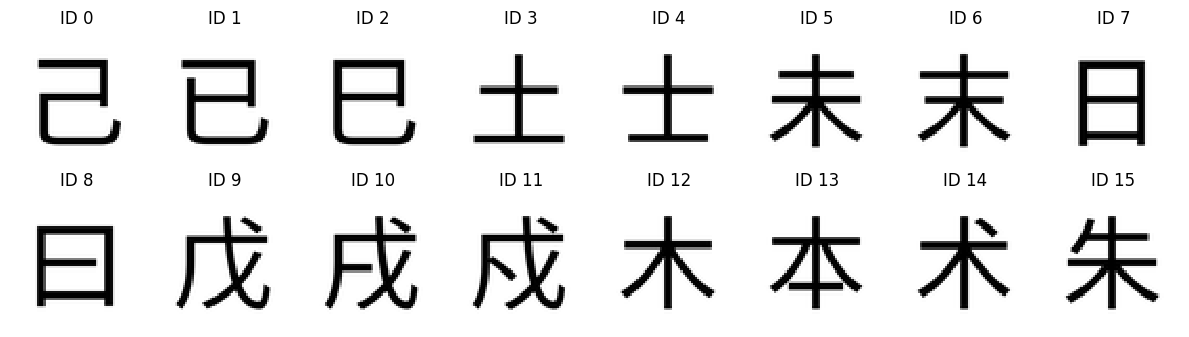

0: 己 / 1: 已 / 2: 巳 / 3: 土 / 4: 士 / 5: 未 / 6: 末 / 7: 日 / 8: 曰 / 9: 戊 / 10: 戌 / 11: 戍 / 12: 木 / 13: 本 / 14: 术 / 15: 朱


In [ ]:
import matplotlib.pyplot as plt
label_data = json.loads((DATA / 'labels.json').read_text(encoding='utf-8'))
with np.load(DATA / 'train.npz', allow_pickle=False) as samples:
    fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
    for index, ax in enumerate(axes.flat):
        ax.imshow(samples['images'][index], cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        class_id = int(samples['labels'][index])
        ax.set_title(f'ID {class_id}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()
print(' / '.join(f"{c['class_id']}: {c['char']}" for c in label_data['characters'][:16]))


## 5. 一轮短跑：检查训练、验证和 Drive 保存

仅每类 2 张训练图和 2 张验证图，共 162 张，运行 1 epoch。这里只检查整个流程，不判断模型好坏。
完成后应有 `config.json`、`history.json`、`best.pt`、`last.pt`。再次运行会复用已完成的短跑。


In [ ]:
def run_training(name, mode, epochs, per_class=None, stop_after=None):
    folder = RUNS / name
    cmd = [sys.executable, '-u', '-m', 'training.train', 'train', '--data', str(DATA),
           '--run-dir', str(folder), '--mode', mode, '--epochs', str(epochs),
           '--batch-size', '64', '--seed', '42']
    if per_class is not None:
        cmd += ['--per-class', str(per_class)]
    if stop_after is not None:
        cmd += ['--stop-after', str(stop_after)]
    if (folder / 'last.pt').exists():
        cmd += ['--resume']
    subprocess.run(cmd, cwd=WORK, check=True)
    for filename in ['config.json', 'history.json', 'best.pt', 'last.pt']:
        assert (folder / filename).is_file(), f'未成功保存 {filename}'
    (folder / 'source_bundle_sha256.txt').write_text(bundle_hash + '\n', encoding='utf-8')
    freeze = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True, check=True)
    (folder / 'environment-pip-freeze.txt').write_text(freeze.stdout, encoding='utf-8')
    print('已保存并检查:', folder)
    return folder

smoke_dir = run_training('smoke_s42_v1', 'smoke', 1, per_class=2)


已保存并检查: /content/drive/MyDrive/hanzi81/runs/smoke_s42_v1


## 6. 小训练集拟合检查

仍使用每类 2 张训练图，训练 20 epoch，验证也在这同一小训练集上，结果只用于排查标签、模型和优化流程。
应看到 loss 明显下降、训练集准确率显著提高并趋向拟合；不把这里的高准确率当成泛化结果。
若仍难以拟合，请先检查曲线和错误，暂不开启完整训练。该 run 与正式基线完全分开。


已保存并检查: /content/drive/MyDrive/hanzi81/runs/overfit_s42_v1
首轮: {'loss': 4.3893788655598955, 'accuracy': 0.012345679012345678, 'macro_accuracy': 0.012345679012345678, 'samples': 162}
末轮: {'loss': 0.062451147830780644, 'accuracy': 1.0, 'macro_accuracy': 1.0, 'samples': 162}


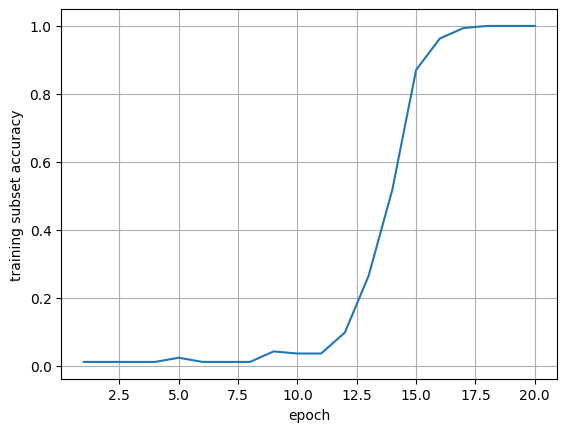

In [ ]:
overfit_dir = run_training('overfit_s42_v1', 'overfit', 20, per_class=2)
overfit_history = json.loads((overfit_dir / 'history.json').read_text(encoding='utf-8'))
print('首轮:', overfit_history[0]['validation'])
print('末轮:', overfit_history[-1]['validation'])
plt.plot([r['epoch'] for r in overfit_history], [r['validation']['accuracy'] for r in overfit_history])
plt.xlabel('epoch'); plt.ylabel('training subset accuracy'); plt.grid(); plt.show()


## 7. 启动 81 字完整基线

前两项检查正常后，把 `START_BASELINE` 改为 `True`。默认先完成 **2/40 epoch**，
这是同一次 40 epoch 计划的前两轮，用于检查耗时和算力消耗，不改变余弦学习率预算。
确认运行正常后，把 `EPOCHS_THIS_SESSION` 改为 `None` 并重新运行本格，即继续完成剩余轮次。

设置：ResNet18 灰度 3×3/stride1 输入、无首层最大池化、随机初始化、交叉熵、AdamW、
batch=64、lr=0.001、weight_decay=0.0001、最多 40 epoch、seed=42。
按 `val_select` macro accuracy 最高选择 `best.pt`，并列取 CE 更低，再并列取更早的 epoch。
40 epoch 是开发预算，是否收敛仍需看结果。

每完成一轮就保存模型、优化器、学习率计划、AMP scaler 和随机状态到 `last.pt`。
运行时被回收后只会从最近完整 epoch 恢复，本轮未完成部分需重跑。不要同时在两个会话写同一个 run。


In [ ]:
START_BASELINE = True  # 前面的检查正常后改为 True
EPOCHS_THIS_SESSION = None  # 先计时两轮；继续完整训练时改为 None
BASELINE_NAME = 'baseline81_s42_v1'
baseline_dir = RUNS / BASELINE_NAME
if START_BASELINE:
    baseline_dir = run_training(BASELINE_NAME, 'baseline', 40, stop_after=EPOCHS_THIS_SESSION)
else:
    print('基线尚未启动。短跑与拟合检查正常后，将 START_BASELINE 改为 True。')


已保存并检查: /content/drive/MyDrive/hanzi81/runs/baseline81_s42_v1


## 8. 查看曲线与开发集报告

默认仅评估 `val_select`；此开发集用于选基线检查点，不能代替独立测试证据。
当前只完成两轮时，以下曲线也是中间结果。`val_graph` 留待基线确定后做一次混淆统计，
测试集 `test` 留待协议冻结后最终评价，本 Notebook 不自动评估二者。


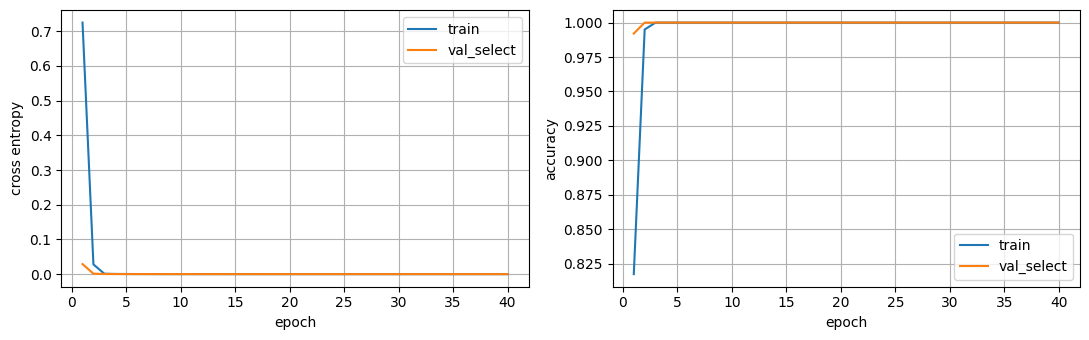

{
  "loss": 2.870661232301234e-06,
  "accuracy": 1.0,
  "macro_accuracy": 1.0,
  "samples": 7776,
  "by_sigma": {
    "0.0": {
      "samples": 2592,
      "accuracy": 1.0
    },
    "0.5": {
      "samples": 2592,
      "accuracy": 1.0
    },
    "1.0": {
      "samples": 2592,
      "accuracy": 1.0
    }
  },
  "split": "val_select",
  "checkpoint_epoch": 38,
  "checkpoint_sha256": "8d65412bf6065253ebce3ca5b0c542788b71e0da391cc335a815f980d828a106"
}


In [ ]:
if (baseline_dir / 'history.json').is_file():
    history = json.loads((baseline_dir / 'history.json').read_text(encoding='utf-8'))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for key, caption in [('train', 'train'), ('validation', 'val_select')]:
        axes[0].plot([r['epoch'] for r in history], [r[key]['loss'] for r in history], label=caption)
        axes[1].plot([r['epoch'] for r in history], [r[key]['accuracy'] for r in history], label=caption)
    axes[0].set_ylabel('cross entropy'); axes[1].set_ylabel('accuracy')
    for ax in axes:
        ax.set_xlabel('epoch'); ax.grid(); ax.legend()
    plt.tight_layout(); plt.show()
    subprocess.run([sys.executable, '-u', '-m', 'training.train', 'evaluate', '--data', str(DATA),
                    '--run-dir', str(baseline_dir), '--split', 'val_select'], cwd=WORK, check=True)
    report = json.loads((baseline_dir / 'evaluation_val_select/metrics.json').read_text(encoding='utf-8'))
    print(json.dumps(report, ensure_ascii=False, indent=2))
else:
    print('基线尚未启动。')


In [ ]:
import json
import sys
import subprocess
import numpy as np
from training.io_utils import digest

history = json.loads(
    (baseline_dir / "history.json").read_text(encoding="utf-8")
)
print("已完成轮数：", history[-1]["epoch"])
assert history[-1]["epoch"] == 40, "请先回第 7 格续训至 40 轮"

report_dir = baseline_dir / "evaluation_val_graph"
metrics_file = report_dir / "metrics.json"

# 已有报告则复用，避免重复评估。
if not metrics_file.exists():
    subprocess.run([
        sys.executable, "-m", "training.train", "evaluate",
        "--data", str(DATA),
        "--run-dir", str(baseline_dir),
        "--split", "val_graph",
    ], cwd=WORK, check=True)

metrics = json.loads(metrics_file.read_text(encoding="utf-8"))
assert metrics["checkpoint_sha256"] == digest(baseline_dir / "best.pt")
print(json.dumps(metrics, ensure_ascii=False, indent=2))

matrix = np.load(report_dir / "confusion.npy")
print("误认总数：", int(matrix.sum() - np.trace(matrix)))

np.fill_diagonal(matrix, 0)
print("满足至少 5 次有向误认的源类别数：",
      int((matrix.max(axis=1) >= 5).sum()))

已完成轮数： 40
{
  "loss": 2.9042040256890797e-06,
  "accuracy": 1.0,
  "macro_accuracy": 1.0,
  "samples": 7776,
  "by_sigma": {
    "0.0": {
      "samples": 2592,
      "accuracy": 1.0
    },
    "0.5": {
      "samples": 2592,
      "accuracy": 1.0
    },
    "1.0": {
      "samples": 2592,
      "accuracy": 1.0
    }
  },
  "split": "val_graph",
  "checkpoint_epoch": 38,
  "checkpoint_sha256": "8d65412bf6065253ebce3ca5b0c542788b71e0da391cc335a815f980d828a106"
}
误认总数： 0
满足至少 5 次有向误认的源类别数： 0


## 9. 保存后的下一步

Drive 路径：`hanzi81/runs/baseline81_s42_v1/`。

- `best.pt`：开发集选出的模型；`last.pt`：完整续训状态。
- `history.json`：每轮损失、准确率和计算时间；`config.json`：超参数、版本、GPU 和数据哈希。
- `evaluation_val_select/`：总体／模糊分项指标、混淆矩阵、54 个预设字对误认、逐图预测。

首次 2 轮后，把 GPU 型号、epoch 耗时、train/val 指标及任何报错反馈给我，再决定后续预算。
完成训练并确认 Drive 中保存成功后，菜单选择“断开连接并删除运行时”，停止占用算力。
不要仅靠关闭浏览器标签页停止计费。Notebook 分享时输出可能随之分享，分享前检查输出。

若显存不足：降低 batch size 后换一个 run 名重新开始，不在同一正式 run 中途改变配置。
若 Colab 更换软件／GPU 导致恢复检查失败：使用原运行时配置恢复，或建立新 run，不能直接删除检查。
更多步骤、故障处理和最终测试命令见上传包内 `colab/README.md`。


## 完整学习过程复盘

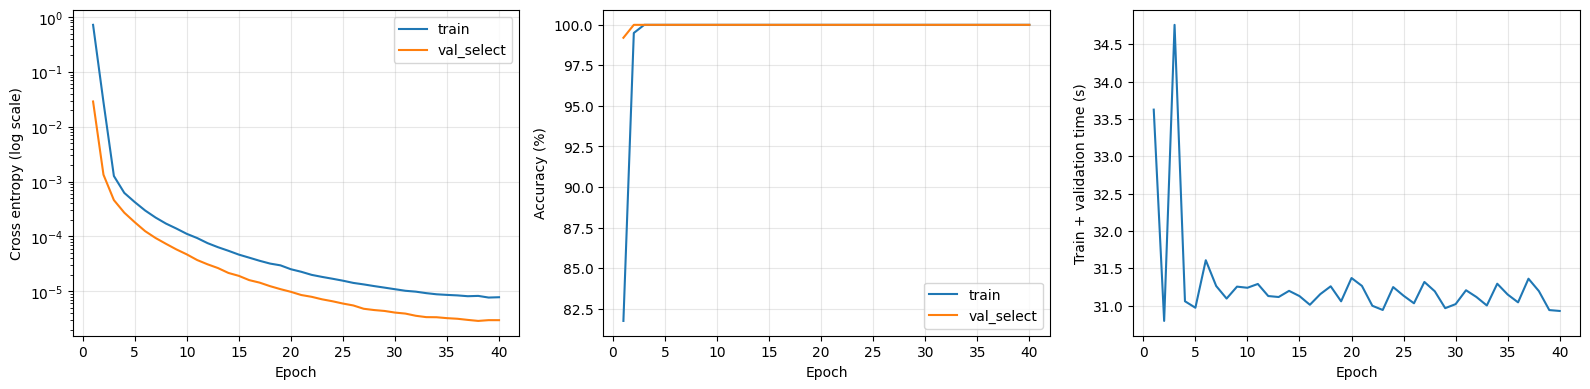

{
  "run": "baseline81_s42_v1",
  "完成轮数": 40,
  "history_sha256": "0f54b1e21979f3414be08e16908e6d2e767c40aec17a8179ecbb854b692a712c",
  "阈值统计_val_select_macro_accuracy": {
    "99%": {
      "首次达到的epoch": 1,
      "持续保持到第40轮的起始epoch": 1
    },
    "99.9%": {
      "首次达到的epoch": 2,
      "持续保持到第40轮的起始epoch": 2
    },
    "100%": {
      "首次达到的epoch": 2,
      "持续保持到第40轮的起始epoch": 2
    }
  },
  "按原规则选出的最佳epoch": 38,
  "最佳轮验证指标": {
    "loss": 2.870661232301234e-06,
    "accuracy": 1.0,
    "macro_accuracy": 1.0,
    "samples": 7776
  },
  "第40轮验证指标": {
    "loss": 2.961677515718424e-06,
    "accuracy": 1.0,
    "macro_accuracy": 1.0,
    "samples": 7776
  },
  "计算耗时_含训练验证_不含检查点保存": {
    "40轮合计分钟": 20.863,
    "首轮秒": 33.624,
    "第2至40轮中位数秒": 31.133,
    "第2至40轮最短秒": 30.796,
    "第2至40轮最长秒": 34.759
  },
  "关键轮次": [
    {
      "epoch": 1,
      "lr": 0.001,
      "train_loss": 0.7249813524109346,
      "train_accuracy": 0.8173868312757202,
      "val_loss": 0.028963854643727034,
      "

In [ ]:
from pathlib import Path
import json
import hashlib
import statistics
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/hanzi81")
RUN = ROOT / "runs/baseline81_s42_v1"
OUT = ROOT / "analyses/baseline81_s42_v1/01_history"

history_path = RUN / "history.json"
config_path = RUN / "config.json"
assert history_path.is_file(), f"找不到日志，请检查 Drive 挂载：{history_path}"
assert config_path.is_file(), f"找不到配置：{config_path}"

history_text = history_path.read_text(encoding="utf-8")
config_text = config_path.read_text(encoding="utf-8")
history = json.loads(history_text)
config = json.loads(config_text)

assert config["mode"] == "baseline"
assert config["seed"] == 42
assert config["epochs"] == 40
assert [r["epoch"] for r in history] == list(range(1, 41)), \
    "日志不是连续完整的 40 轮，请先把报错反馈给我"
assert all(r["validation_split"] == "val_select" for r in history)

# “首次达到”与“从此轮起一直保持到第40轮”分别统计。
thresholds = {}
for name, threshold in [("99%", 0.99), ("99.9%", 0.999), ("100%", 1.0)]:
    passed = [
        r["validation"]["macro_accuracy"] >= threshold
        for r in history
    ]
    first = next(
        (history[i]["epoch"] for i in range(len(history)) if passed[i]),
        None
    )
    sustained = next(
        (history[i]["epoch"] for i in range(len(history)) if all(passed[i:])),
        None
    )
    thresholds[name] = {
        "首次达到的epoch": first,
        "持续保持到第40轮的起始epoch": sustained,
    }

# 与原训练器一致：macro accuracy 优先，其次低 loss，再其次早轮次。
selected = max(
    history,
    key=lambda r: (
        r["validation"]["macro_accuracy"],
        -r["validation"]["loss"],
        -r["epoch"],
    ),
)

snapshots = []
for epoch in [1, 2, 5, 10, 20, 30, 38, 40]:
    row = history[epoch - 1]
    snapshots.append({
        "epoch": epoch,
        "lr": row["lr"],
        "train_loss": row["train"]["loss"],
        "train_accuracy": row["train"]["accuracy"],
        "val_loss": row["validation"]["loss"],
        "val_accuracy": row["validation"]["accuracy"],
    })

times = [float(r["seconds_compute"]) for r in history]
summary = {
    "run": RUN.name,
    "完成轮数": len(history),
    "history_sha256": hashlib.sha256(history_path.read_bytes()).hexdigest(),
    "阈值统计_val_select_macro_accuracy": thresholds,
    "按原规则选出的最佳epoch": selected["epoch"],
    "最佳轮验证指标": selected["validation"],
    "第40轮验证指标": history[-1]["validation"],
    "计算耗时_含训练验证_不含检查点保存": {
        "40轮合计分钟": round(sum(times) / 60, 3),
        "首轮秒": round(times[0], 3),
        "第2至40轮中位数秒": round(statistics.median(times[1:]), 3),
        "第2至40轮最短秒": round(min(times[1:]), 3),
        "第2至40轮最长秒": round(max(times[1:]), 3),
    },
    "关键轮次": snapshots,
}

OUT.mkdir(parents=True, exist_ok=True)
(OUT / "summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
# 留存本次分析对应的完整输入，原 run 文件保持原样。
(OUT / "history_snapshot.json").write_text(history_text, encoding="utf-8")
(OUT / "config_snapshot.json").write_text(config_text, encoding="utf-8")

epochs = [r["epoch"] for r in history]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for key, label in [("train", "train"), ("validation", "val_select")]:
    axes[0].plot(
        epochs, [max(r[key]["loss"], 1e-12) for r in history],
        label=label,
    )
    axes[1].plot(
        epochs, [100 * r[key]["accuracy"] for r in history],
        label=label,
    )

axes[0].set_yscale("log")
axes[0].set_ylabel("Cross entropy (log scale)")
axes[1].set_ylabel("Accuracy (%)")
axes[2].plot(epochs, times)
axes[2].set_ylabel("Train + validation time (s)")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
axes[0].legend()
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / "history_curves.png", dpi=180)
plt.show()

print(json.dumps(summary, ensure_ascii=False, indent=2))
print("\n分析已保存到：", OUT)

## 分类间隔与字对分析

In [ ]:
from pathlib import Path
import json
import numpy as np
import torch

assert "DATA" in globals(), "请先运行原 Notebook 第 1～3 步"
assert torch.cuda.is_available(), "请连接 GPU 运行时"

from training import train as T
from training.io_utils import digest, verify_dataset, write_json

DATA = Path(DATA)
RUN = Path("/content/drive/MyDrive/hanzi81/runs/baseline81_s42_v1")
OUT = Path("/content/drive/MyDrive/hanzi81/analyses/baseline81_s42_v1/02_margins")
SPLIT = "val_graph"
device = torch.device("cuda")

# 核对原模型、数据、代码和运行环境。
expected_checkpoint = (
    "8d65412bf6065253ebce3ca5b0c542788b71e0da391cc335a815f980d828a106"
)
checkpoint_hash = digest(RUN / "best.pt")
assert checkpoint_hash == expected_checkpoint, "best.pt 与已记录模型不一致"

manifest = verify_dataset(DATA)
checkpoint = torch.load(
    RUN / "best.pt", map_location="cpu", weights_only=True
)
cfg = checkpoint["config"]

assert checkpoint["epoch"] == 38
assert cfg["mode"] == "baseline"
assert cfg["data_sha256"] == digest(DATA / "manifest.json")
assert cfg["trainer_sha256"] == digest(T.__file__)
assert cfg["io_sha256"] == digest(Path(T.__file__).with_name("io_utils.py"))
assert cfg["environment"] == T.environment(device), \
    "运行环境与原实验不同，请把报错和当前环境反馈给我"

label_data = json.loads((DATA / "labels.json").read_text(encoding="utf-8"))
characters = label_data["characters"]
id_to_char = {int(c["class_id"]): c["char"] for c in characters}
char_to_id = {v: k for k, v in id_to_char.items()}
n_classes = len(characters)

conditions = json.loads(
    (DATA / "conditions.json").read_text(encoding="utf-8")
)[SPLIT]
dataset = T.GlyphDataset(DATA, SPLIT)
loader = T.loader_for(dataset, cfg["batch_size"], device)

T.seed_everything(cfg["seed"])
model = T.model_for(n_classes).to(device)
model.load_state_dict(checkpoint["model"])
model.eval()

# 保持与原评估一致的 FP32 前向。
logits_all = np.empty((len(dataset), n_classes), dtype=np.float32)
loss_sum = 0.0
with torch.inference_mode(), torch.autocast("cuda", enabled=False):
    for images, labels, indexes in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        logits = model(images)
        assert torch.isfinite(logits).all(), "出现非有限 logits"
        loss = torch.nn.functional.cross_entropy(logits, labels)
        loss_sum += loss.item() * len(labels)
        logits_all[indexes.numpy()] = logits.cpu().numpy()

truth = dataset.labels.astype(np.int64)
rows = np.arange(len(truth))
pred = logits_all.argmax(axis=1)
correct = pred == truth
sigma = np.array([
    conditions[int(i)]["sigma"] for i in dataset.condition_ids
])

# FP32 logits 转为 float64 后做差与概率统计，减少后处理舍入。
z = logits_all.astype(np.float64)
wrong_scores = z.copy()
wrong_scores[rows, truth] = -np.inf
competitor = wrong_scores.argmax(axis=1)
margin = z[rows, truth] - z[rows, competitor]

exp_scores = np.exp(z - z.max(axis=1, keepdims=True))
true_probability = exp_scores[rows, truth] / exp_scores.sum(axis=1)

def stats(values):
    values = np.asarray(values)
    return {
        "min": float(values.min()),
        "p05": float(np.quantile(values, 0.05)),
        "median": float(np.median(values)),
        "p95": float(np.quantile(values, 0.95)),
        "max": float(values.max()),
    }

overall = {
    "samples": len(truth),
    "errors": int((~correct).sum()),
    "accuracy": float(correct.mean()),
    "loss_fp32": loss_sum / len(truth),
    "margin": stats(margin),
    "true_class_probability": stats(true_probability),
}

by_sigma = {}
for s in sorted(np.unique(sigma)):
    mask = sigma == s
    by_sigma[str(float(s))] = {
        "samples": int(mask.sum()),
        "accuracy": float(correct[mask].mean()),
        "margin": stats(margin[mask]),
    }

# 每类的竞争类别统计：即使预测正确，也会有最强竞争类别。
class_reports = []
for class_id in range(n_classes):
    mask = truth == class_id
    counts = np.bincount(competitor[mask], minlength=n_classes)
    rival = int(counts.argmax())
    class_reports.append({
        "class_id": class_id,
        "char": id_to_char[class_id],
        "samples": int(mask.sum()),
        "errors": int((~correct[mask]).sum()),
        "margin": stats(margin[mask]),
        "most_frequent_competitor": id_to_char[rival],
        "competitor_count": int(counts[rival]),
    })
class_reports.sort(key=lambda r: (r["margin"]["p05"], r["margin"]["median"]))

# 预设字对：分别计算 a 样本上的 z_a-z_b，以及 b 样本上的 z_b-z_a。
pair_reports = []
for pair in label_data["pairs"]:
    a, b = char_to_id[pair["a"]], char_to_id[pair["b"]]
    mask_a, mask_b = truth == a, truth == b
    a_stats = stats(z[mask_a, a] - z[mask_a, b])
    b_stats = stats(z[mask_b, b] - z[mask_b, a])
    pair_reports.append({
        "a": pair["a"],
        "b": pair["b"],
        "a_against_b_margin": a_stats,
        "b_against_a_margin": b_stats,
        "weaker_direction_p05": min(a_stats["p05"], b_stats["p05"]),
        "a_to_b_errors": int((pred[mask_a] == b).sum()),
        "b_to_a_errors": int((pred[mask_b] == a).sum()),
    })
pair_reports.sort(key=lambda r: r["weaker_direction_p05"])

weak_samples = []
for index in np.argsort(margin)[:10]:
    index = int(index)
    condition = conditions[int(dataset.condition_ids[index])]
    weak_samples.append({
        "index": index,
        "true_char": id_to_char[int(truth[index])],
        "predicted_char": id_to_char[int(pred[index])],
        "competitor": id_to_char[int(competitor[index])],
        "margin": float(margin[index]),
        "sigma": condition["sigma"],
        "dx": condition["dx"],
        "dy": condition["dy"],
    })

report = {
    "split": SPLIT,
    "checkpoint_epoch": checkpoint["epoch"],
    "checkpoint_sha256": checkpoint_hash,
    "data_sha256": cfg["data_sha256"],
    "environment": T.environment(device),
    "overall": overall,
    "by_sigma": by_sigma,
    "classes_sorted_by_margin_p05": class_reports,
    "pairs_sorted_by_weaker_direction_p05": pair_reports,
    "ten_smallest_margin_samples": weak_samples,
}
summary = {
    "split": SPLIT,
    "checkpoint_epoch": checkpoint["epoch"],
    "overall": overall,
    "by_sigma": by_sigma,
    "five_smallest_margin_classes": class_reports[:5],
    "five_smallest_margin_pairs": pair_reports[:5],
    "five_smallest_margin_samples": weak_samples[:5],
}

OUT.mkdir(parents=True, exist_ok=True)
write_json(OUT / "full_report.json", report)
write_json(OUT / "summary.json", summary)
np.savez_compressed(
    OUT / "logits_val_graph.npz",
    logits=logits_all,
    labels=truth,
    condition_ids=dataset.condition_ids,
)

del model, checkpoint
torch.cuda.empty_cache()

print(json.dumps(summary, ensure_ascii=False, indent=2))
print("\n分析已保存到：", OUT)

{
  "split": "val_graph",
  "checkpoint_epoch": 38,
  "overall": {
    "samples": 7776,
    "errors": 0,
    "accuracy": 1.0,
    "loss_fp32": 2.9042040256890797e-06,
    "margin": {
      "min": 12.229050636291504,
      "p05": 13.35326287150383,
      "median": 14.284753561019897,
      "p95": 15.023745447397232,
      "max": 15.664948999881744
    },
    "true_class_probability": {
      "min": 0.9999898098627066,
      "p05": 0.9999952790933996,
      "median": 0.9999972478363516,
      "p95": 0.9999983906145968,
      "max": 0.9999990704169651
    }
  },
  "by_sigma": {
    "0.0": {
      "samples": 2592,
      "accuracy": 1.0,
      "margin": {
        "min": 12.335483074188232,
        "p05": 13.30598691701889,
        "median": 14.267489969730377,
        "p95": 14.955464267730713,
        "max": 15.574845016002655
      }
    },
    "0.5": {
      "samples": 2592,
      "accuracy": 1.0,
      "margin": {
        "min": 12.229050636291504,
        "p05": 13.449354660511016,
   

## 算力与保存耗时测量

In [ ]:
from pathlib import Path
import hashlib
import subprocess
import sys
from google.colab import files

assert "WORK" in globals() and "DATA" in globals(), \
    "请先运行原 Notebook 第 1～3 步，恢复 GPU、Drive、代码和数据"

uploaded = files.upload()  # 只选择 profile_runtime.py
assert len(uploaded) == 1, "请只上传这一个计时脚本"
filename, content = next(iter(uploaded.items()))

expected_sha256 = (
    "131d07fadea99eece5d0c1c4179e454b8149f8ec960a3c6ba2229f40886052bc"
)
assert hashlib.sha256(content).hexdigest() == expected_sha256, \
    "脚本内容不匹配，请选择上面链接中的原文件"

script = Path("/content/hanzi81_profile_runtime.py")
script.write_bytes(content)

subprocess.run(
    [
        sys.executable, "-u", str(script),
        "--work", str(WORK),
        "--data", str(DATA),
        "--root", "/content/drive/MyDrive/hanzi81",
    ],
    cwd=str(WORK),
    check=True,
)

Saving profile_runtime.py to profile_runtime.py


CompletedProcess(args=['/usr/bin/python3', '-u', '/content/hanzi81_profile_runtime.py', '--work', '/content/hanzi81-e477bdd4894e', '--data', '/content/hanzi81-e477bdd4894e/training/data/baseline81-v2', '--root', '/content/drive/MyDrive/hanzi81'], returncode=0)

In [ ]:
from pathlib import Path
import json

ROOT = Path(
    "/content/drive/MyDrive/hanzi81/"
    "analyses/baseline81_s42_v1/06_profile"
)
reports = sorted(ROOT.glob("*/summary.json"), key=lambda p: p.parent.name)
assert reports, f"没有找到完整报告，请把此报错发给我：{ROOT}"

latest = reports[-1]
report = json.loads(latest.read_text(encoding="utf-8"))

print("读取报告：", latest)
print(json.dumps(report, ensure_ascii=False, indent=2))

读取报告： /content/drive/MyDrive/hanzi81/analyses/baseline81_s42_v1/06_profile/20261012T150314Z_396b4588/summary.json
{
  "purpose": "runtime_profile_only_not_scientific_results",
  "output_directory": "/content/drive/MyDrive/hanzi81/analyses/baseline81_s42_v1/06_profile/20261012T150314Z_396b4588",
  "environment": {
    "python": "3.13.15",
    "torch": "2.11.0+cu130",
    "torchvision": "0.26.0+cu130",
    "numpy": "2.1.3",
    "cuda": "13.0",
    "cudnn": 92700,
    "device": "cuda",
    "gpu": "Tesla T4"
  },
  "batch_size": 64,
  "memory_before": {
    "device_free_gib": 14.24395751953125,
    "device_total_gib": 14.56317138671875,
    "this_process_allocated_gib": 0.0
  },
  "dataset_loads": [
    {
      "split": "train",
      "samples": 15552,
      "seconds": 0.25209123599984196
    },
    {
      "split": "val_select",
      "samples": 7776,
      "seconds": 0.12047151299998404
    }
  ],
  "epochs": [
    {
      "epoch": 1,
      "train_seconds": 23.478998246999936,
      "tra

In [ ]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys

LC_ROOT = Path("/content/drive/MyDrive/hanzi81")
LC_SUITE = (
    LC_ROOT / "analyses/baseline81_s42_v1/"
    "03_learning_curve/steps2430_s42_v1"
)
WORK = Path("/content/hanzi81-e477bdd4894e")
DATA = WORK / "training/data/baseline81-v2"
LC_SCRIPT = Path("/content/hanzi81_learning_curve.py")

assert (LC_SUITE / "plan.json").is_file(), \
    "请先运行原 Notebook 的 Drive 挂载单元"
assert (WORK / "training/train.py").is_file() and (DATA / "train.npz").is_file(), \
    "本地运行时文件已丢失，请先运行原 Notebook 第 1～3 步，再运行本格"

plan = json.loads((LC_SUITE / "plan.json").read_text(encoding="utf-8"))
content = (LC_SUITE / "learning_curve.py").read_bytes()
assert hashlib.sha256(content).hexdigest() == plan["curve_script_sha256"], \
    "保存的脚本与实验协议不匹配，请反馈此报错"
LC_SCRIPT.write_bytes(content)

def run_learning_curve(action):
    cmd = [
        sys.executable, "-u", str(LC_SCRIPT), action,
        "--work", str(WORK),
        "--data", str(DATA),
        "--root", str(LC_ROOT),
    ]
    with subprocess.Popen(
        cmd, cwd=str(WORK),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True, encoding="utf-8", errors="replace",
        bufsize=1,
    ) as process:
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
            returncode = process.wait()
        except BaseException:
            process.terminate()
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
            raise
        if returncode:
            raise RuntimeError("运行失败，请把上面的报错发给我")

print("辅助函数已恢复，可以运行原来的第②格。")

辅助函数已恢复，可以运行原来的第②格。


In [ ]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys
from google.colab import files

assert "WORK" in globals() and "DATA" in globals(), \
    "请先运行原 Notebook 第 1～3 步"

uploaded = files.upload()  # 只选择 learning_curve.py
assert len(uploaded) == 1
_, content = next(iter(uploaded.items()))

expected = "2b098c465e94fd1909c159c1a64b59745e914c13023e1a23d8a3445e2231272d"
assert hashlib.sha256(content).hexdigest() == expected, "请上传原始脚本文件"

LC_SCRIPT = Path("/content/hanzi81_learning_curve.py")
LC_SCRIPT.write_bytes(content)
LC_ROOT = Path("/content/drive/MyDrive/hanzi81")
LC_SUITE = (
    LC_ROOT / "analyses/baseline81_s42_v1/"
    "03_learning_curve/steps2430_s42_v1"
)

def run_learning_curve(action):
    cmd = [
        sys.executable, "-u", str(LC_SCRIPT), action,
        "--work", str(WORK),
        "--data", str(DATA),
        "--root", str(LC_ROOT),
    ]
    with subprocess.Popen(
        cmd, cwd=str(WORK),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True, encoding="utf-8", errors="replace",
        bufsize=1,
    ) as process:
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
            returncode = process.wait()
        except BaseException:
            process.terminate()
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
            raise
        if returncode:
            raise RuntimeError("运行失败，请把上面的报错发给我")

run_learning_curve("prepare")

KeyboardInterrupt: 

In [ ]:
print("LC_ONECELL_V1：开始读取已保存实验", flush=True)

from pathlib import Path
import hashlib
import json
import subprocess
import sys
import matplotlib.pyplot as plt

root = Path("/content/drive/MyDrive/hanzi81")
suite = (
    root / "analyses/baseline81_s42_v1/"
    "03_learning_curve/steps2430_s42_v1"
)
work = Path("/content/hanzi81-e477bdd4894e")
data = work / "training/data/baseline81-v2"
script = Path("/content/hanzi81_learning_curve.py")

assert (suite / "plan.json").is_file(), \
    "请先挂载 Google Drive，再运行本格"
assert (work / "training/train.py").is_file(), \
    "本地代码已丢失，请先运行原 Notebook 第 1～3 步，再运行本格"
assert (data / "train.npz").is_file(), \
    "本地数据已丢失，请先运行原 Notebook 第 1～3 步，再运行本格"

# 从已冻结的实验目录恢复脚本。
plan = json.loads((suite / "plan.json").read_text(encoding="utf-8"))
content = (suite / "learning_curve.py").read_bytes()
assert hashlib.sha256(content).hexdigest() == plan["curve_script_sha256"], \
    "脚本校验失败，请反馈此报错"
script.write_bytes(content)

cmd = [
    sys.executable, "-u", str(script), "train",
    "--work", str(work),
    "--data", str(data),
    "--root", str(root),
]

print("开始训练；已有完整保存的进度将自动恢复。", flush=True)

# 在本格直接启动子进程，并实时显示训练日志。
with subprocess.Popen(
    cmd,
    cwd=str(work),
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    encoding="utf-8",
    errors="replace",
    bufsize=1,
) as process:
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
    except BaseException:
        process.terminate()
        try:
            process.wait(timeout=10)
        except subprocess.TimeoutExpired:
            process.kill()
            process.wait()
        raise

if returncode != 0:
    raise RuntimeError(
        f"训练进程退出码为 {returncode}，请把上面的完整报错发给我"
    )

# 读取最终结果并绘图。
summary = json.loads(
    (suite / "summary.json").read_text(encoding="utf-8")
)
assert summary["all_complete"], "还有未完成的档位，请反馈训练输出"

results = summary["results"]
sizes = [r["per_class"] for r in results]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for key, label in [
    ("last_completed_validation", "Final: fixed budget"),
    ("best_validation", "Selected best"),
]:
    axes[0].plot(
        sizes, [100 * r[key]["accuracy"] for r in results],
        "o-", label=label,
    )
    axes[1].plot(
        sizes, [max(r[key]["loss"], 1e-12) for r in results],
        "o-", label=label,
    )

axes[0].set_ylabel("val_select accuracy (%)")
axes[1].set_ylabel("val_select cross entropy")
axes[1].set_yscale("log")

for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(sizes, labels=[str(n) for n in sizes])
    ax.set_xlabel("Unique training images per class")
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
fig.savefig(suite / "learning_curve.png", dpi=180)
plt.show()

print("四档均已完成。结果目录：", suite)